In [1]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("creditcard.csv")

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

display(df.head())


Dataset loaded successfully!
Dataset shape: (284807, 31)


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


## 1. Dataset Inspection and Class Imbalance Analysis

The Credit Card Fraud Detection dataset contains 284,807 financial transactions and 31 columns, including transaction time, 28 anonymized features (V1–V28), transaction amount, and the target variable Class. Class 0 represents legitimate transactions, while Class 1 represents fraudulent transactions. Since fraudulent transactions are expected to be rare, class distribution and fraud percentage are analysed before building the classification models.

Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 284807 entries, 0 to 284806
Data columns (total 31 columns):
 #   Column  Non-Null Count   Dtype  
---  ------  --------------   -----  
 0   Time    284807 non-null  float64
 1   V1      284807 non-null  float64
 2   V2      284807 non-null  float64
 3   V3      284807 non-null  float64
 4   V4      284807 non-null  float64
 5   V5      284807 non-null  float64
 6   V6      284807 non-null  float64
 7   V7      284807 non-null  float64
 8   V8      284807 non-null  float64
 9   V9      284807 non-null  float64
 10  V10     284807 non-null  float64
 11  V11     284807 non-null  float64
 12  V12     284807 non-null  float64
 13  V13     284807 non-null  float64
 14  V14     284807 non-null  float64
 15  V15     284807 non-null  float64
 16  V16     284807 non-null  float64
 17  V17     284807 non-null  float64
 18  V18     284807 non-null  float64
 19  V19     284807 non-null  float64
 20  V20     284807 non-null  float64
 21  

,Count
Class,
0,284315
1,492


Legitimate transactions: 284315 (99.8273%)
Fraudulent transactions: 492 (0.1727%)


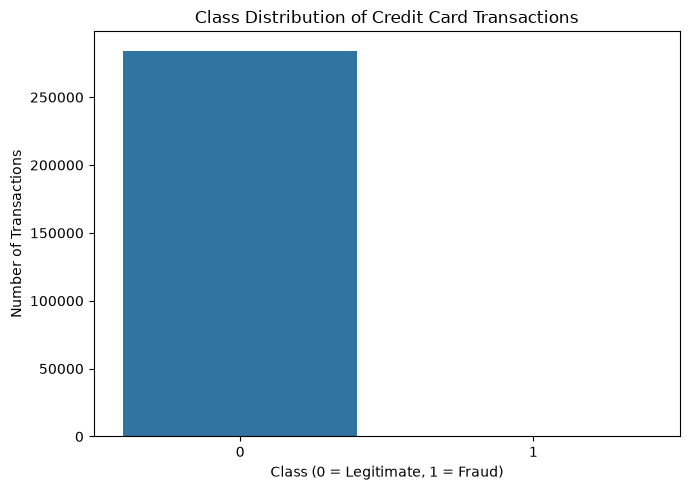

In [2]:

print("Dataset information:")
df.info()

print("\nMissing values:")
print(df.isnull().sum().sum())

class_counts = df["Class"].value_counts().sort_index()
fraud_percentage = (class_counts[1] / len(df)) * 100
normal_percentage = (class_counts[0] / len(df)) * 100

print("\nTransaction Class Counts:")
display(class_counts.to_frame(name="Count"))

print(f"Legitimate transactions: {class_counts[0]} ({normal_percentage:.4f}%)")
print(f"Fraudulent transactions: {class_counts[1]} ({fraud_percentage:.4f}%)")

plt.figure(figsize=(7, 5))
sns.countplot(data=df, x="Class")
plt.title("Class Distribution of Credit Card Transactions")
plt.xlabel("Class (0 = Legitimate, 1 = Fraud)")
plt.ylabel("Number of Transactions")
plt.tight_layout()
plt.show()


## 2. Exploratory Data Analysis

Exploratory Data Analysis (EDA) is performed to understand transaction amounts and the timing of transactions for legitimate and fraudulent activities. Comparing these patterns may reveal differences between the two classes. However, the observed patterns alone cannot prove that a transaction is fraudulent.

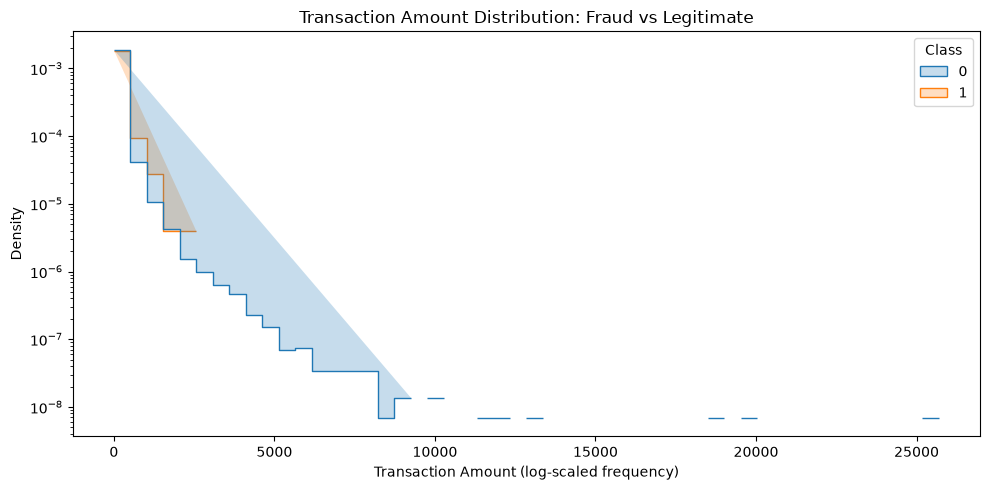

In [3]:

plt.figure(figsize=(10, 5))

sns.histplot(
    data=df,
    x="Amount",
    hue="Class",
    bins=50,
    log_scale=(False, True),
    element="step",
    stat="density",
    common_norm=False
)

plt.title("Transaction Amount Distribution: Fraud vs Legitimate")
plt.xlabel("Transaction Amount (log-scaled frequency)")
plt.ylabel("Density")
plt.tight_layout()
plt.show()


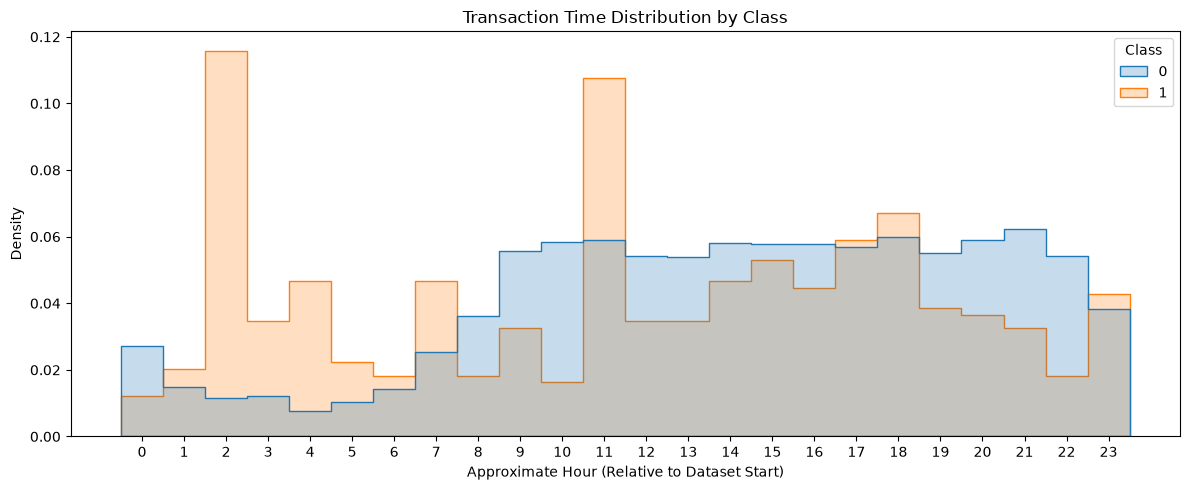

In [4]:

df["Hour"] = ((df["Time"] // 3600) % 24).astype(int)

plt.figure(figsize=(12, 5))

sns.histplot(
    data=df,
    x="Hour",
    hue="Class",
    bins=np.arange(25) - 0.5,
    multiple="layer",
    stat="density",
    common_norm=False,
    element="step"
)

plt.title("Transaction Time Distribution by Class")
plt.xlabel("Approximate Hour (Relative to Dataset Start)")
plt.ylabel("Density")
plt.xticks(range(24))
plt.tight_layout()
plt.show()


## 3. Why Accuracy Is Misleading for Fraud Detection

The dataset is highly imbalanced because only 492 out of 284,807 transactions (approximately 0.1727%) are fraudulent. A model that predicts every transaction as legitimate could achieve approximately 99.83% accuracy while failing to detect every fraudulent transaction. Therefore, accuracy alone is not a reliable measure of fraud detection performance.

Precision measures how many transactions predicted as fraud are actually fraudulent. Recall measures how many actual fraudulent transactions are detected. F1-score balances precision and recall, while ROC-AUC measures how well the model distinguishes fraudulent from legitimate transactions across different classification thresholds. These metrics provide a more meaningful evaluation for imbalanced fraud detection.

## 4. Handling Class Imbalance

The class distribution is highly imbalanced, with fraudulent transactions representing only approximately 0.1727% of the dataset. In this project, the `class_weight="balanced"` option is used for the classification models. It automatically assigns higher weights to the minority class during training, encouraging the models to pay more attention to fraudulent transactions. The train-test split is stratified to preserve the original class proportions, and imbalance handling is applied only during model training.

In [5]:

from sklearn.model_selection import train_test_split

X = df.drop(columns=["Class", "Hour"])
y = df["Class"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

print("\nTraining class distribution:")
display(y_train.value_counts().sort_index().to_frame(name="Count"))

print("\nTesting class distribution:")
display(y_test.value_counts().sort_index().to_frame(name="Count"))

print("\nFraud cases in training:", int(y_train.sum()))
print("Fraud cases in testing:", int(y_test.sum()))


Training samples: 227845
Testing samples: 56962

Training class distribution:


,Count
Class,
0,227451
1,394



Testing class distribution:


,Count
Class,
0,56864
1,98



Fraud cases in training: 394
Fraud cases in testing: 98


## 5. Model Training

Two classification algorithms are trained to detect fraudulent transactions: Logistic Regression and Random Forest. Logistic Regression provides a baseline classifier, while Random Forest can learn more complex relationships between transaction features. Both models use class weighting to account for the severe imbalance between legitimate and fraudulent transactions. The data is split using stratified sampling, and the test set is kept separate for final evaluation.

In [6]:

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

models = {
    "Logistic Regression": Pipeline([
        ("scaler", StandardScaler()),
        ("classifier", LogisticRegression(
            class_weight="balanced",
            max_iter=1000,
            random_state=42
        ))
    ]),
    "Random Forest": RandomForestClassifier(
        n_estimators=100,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    )
}

for name, model in models.items():
    print("Training:", name)
    model.fit(X_train, y_train)
    print(name, "trained successfully!")


Training: Logistic Regression
Logistic Regression trained successfully!
Training: Random Forest
Random Forest trained successfully!


## 6. Model Evaluation

The trained models are evaluated using Precision, Recall, F1-score, ROC-AUC, and confusion matrices. Precision measures the proportion of predicted fraud cases that are truly fraudulent, while Recall measures the proportion of actual fraud cases detected by the model. F1-score balances Precision and Recall. ROC-AUC measures the model's ability to distinguish fraudulent transactions from legitimate ones across different classification thresholds. These metrics are more informative than accuracy alone for this highly imbalanced dataset.


Logistic Regression
Accuracy: 0.9755
Precision: 0.061
Recall: 0.9184
F1-Score: 0.1144
ROC-AUC: 0.9721

Classification Report:
              precision    recall  f1-score   support

  Legitimate       1.00      0.98      0.99     56864
       Fraud       0.06      0.92      0.11        98

    accuracy                           0.98     56962
   macro avg       0.53      0.95      0.55     56962
weighted avg       1.00      0.98      0.99     56962



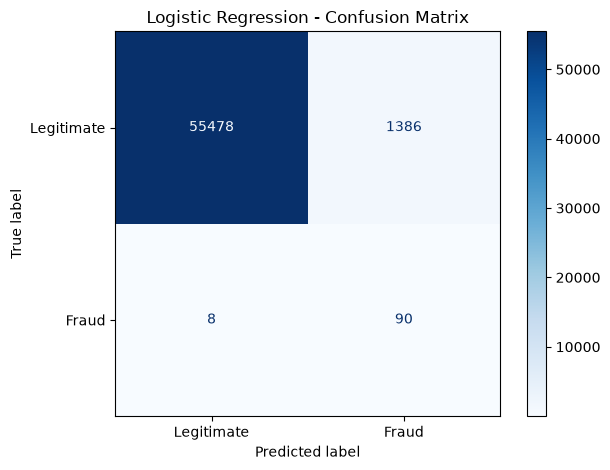


Random Forest
Accuracy: 0.9995
Precision: 0.9059
Recall: 0.7857
F1-Score: 0.8415
ROC-AUC: 0.9573

Classification Report:
              precision    recall  f1-score   support

  Legitimate       1.00      1.00      1.00     56864
       Fraud       0.91      0.79      0.84        98

    accuracy                           1.00     56962
   macro avg       0.95      0.89      0.92     56962
weighted avg       1.00      1.00      1.00     56962



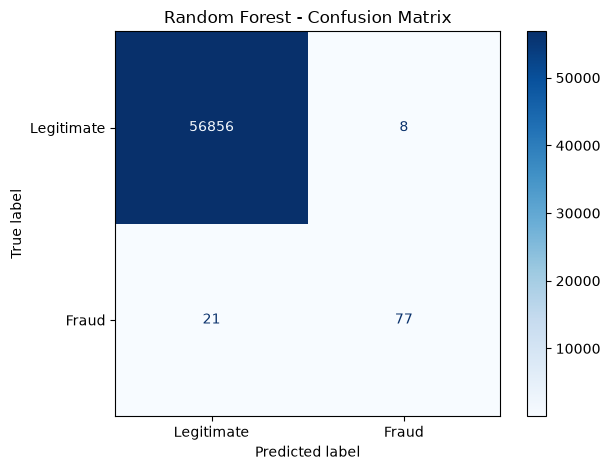

In [7]:

from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    roc_curve,
    accuracy_score
)

evaluation_results = {}
roc_data = {}

for name, model in models.items():
    y_pred = model.predict(X_test)
    y_prob = model.predict_proba(X_test)[:, 1]

    precision = precision_score(y_test, y_pred, zero_division=0)
    recall = recall_score(y_test, y_pred, zero_division=0)
    f1 = f1_score(y_test, y_pred, zero_division=0)
    auc = roc_auc_score(y_test, y_prob)
    accuracy = accuracy_score(y_test, y_pred)

    evaluation_results[name] = {
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1-Score": f1,
        "ROC-AUC": auc
    }

    roc_data[name] = roc_curve(y_test, y_prob)

    print("\n", "=" * 45)
    print(name)
    print("=" * 45)
    print("Accuracy:", round(accuracy, 4))
    print("Precision:", round(precision, 4))
    print("Recall:", round(recall, 4))
    print("F1-Score:", round(f1, 4))
    print("ROC-AUC:", round(auc, 4))

    print("\nClassification Report:")
    print(classification_report(
        y_test,
        y_pred,
        target_names=["Legitimate", "Fraud"],
        zero_division=0
    ))

    cm = confusion_matrix(y_test, y_pred, labels=[0, 1])
    display_cm = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=["Legitimate", "Fraud"]
    )
    display_cm.plot(cmap="Blues", values_format="d")
    plt.title(name + " - Confusion Matrix")
    plt.tight_layout()
    plt.show()


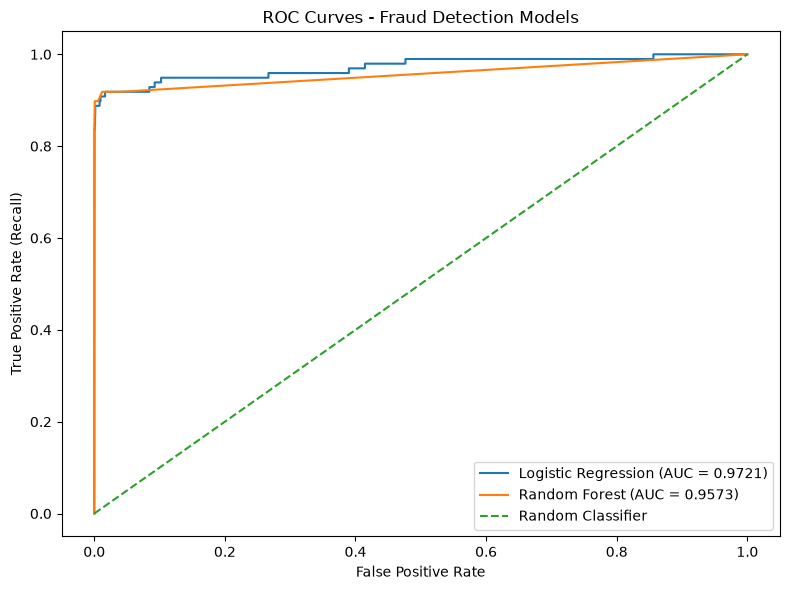

In [8]:

plt.figure(figsize=(8, 6))

for name, (fpr, tpr, thresholds) in roc_data.items():
    auc = evaluation_results[name]["ROC-AUC"]
    plt.plot(fpr, tpr, label=f"{name} (AUC = {auc:.4f})")

plt.plot([0, 1], [0, 1], linestyle="--", label="Random Classifier")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate (Recall)")
plt.title("ROC Curves - Fraud Detection Models")
plt.legend()
plt.tight_layout()
plt.show()


## 7. Feature Importance Analysis

Feature importance analysis helps identify which transaction attributes contribute most to fraud detection. Random Forest provides feature importance scores based on how much each feature contributes to reducing impurity across its decision trees. Logistic Regression coefficients indicate how features influence the model's prediction after standardisation. These results help interpret the models, but they do not establish causation.

Top 15 Important Features:


,Feature,Importance
14,V14,0.19104
10,V10,0.10685
4,V4,0.10564
12,V12,0.09760
17,V17,0.09034
3,V3,0.06592
11,V11,0.04634
16,V16,0.04465
2,V2,0.03833
9,V9,0.02544


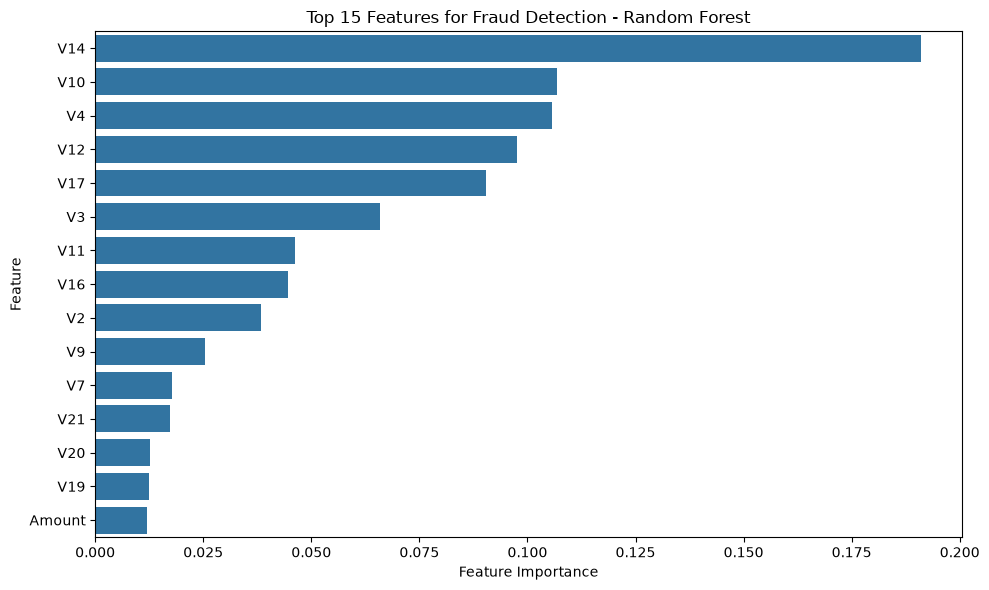

In [9]:

rf_model = models["Random Forest"]

importance_df = pd.DataFrame({
    "Feature": X_train.columns,
    "Importance": rf_model.feature_importances_
})

importance_df = importance_df.sort_values(
    by="Importance",
    ascending=False
)

print("Top 15 Important Features:")
display(importance_df.head(15).round(5))

plt.figure(figsize=(10, 6))
sns.barplot(
    data=importance_df.head(15),
    x="Importance",
    y="Feature"
)
plt.title("Top 15 Features for Fraud Detection - Random Forest")
plt.xlabel("Feature Importance")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()


Top 15 Logistic Regression Coefficients:


,Feature,Coefficient,Absolute Coefficient
29,Amount,2.36728,2.36728
1,V1,1.72386,1.72386
14,V14,-1.49496,1.49496
4,V4,1.33943,1.33943
10,V10,-1.33500,1.33500
5,V5,1.21438,1.21438
12,V12,-1.12789,1.12789
16,V16,-0.99638,0.99638
17,V17,-0.99218,0.99218
2,V2,0.93208,0.93208


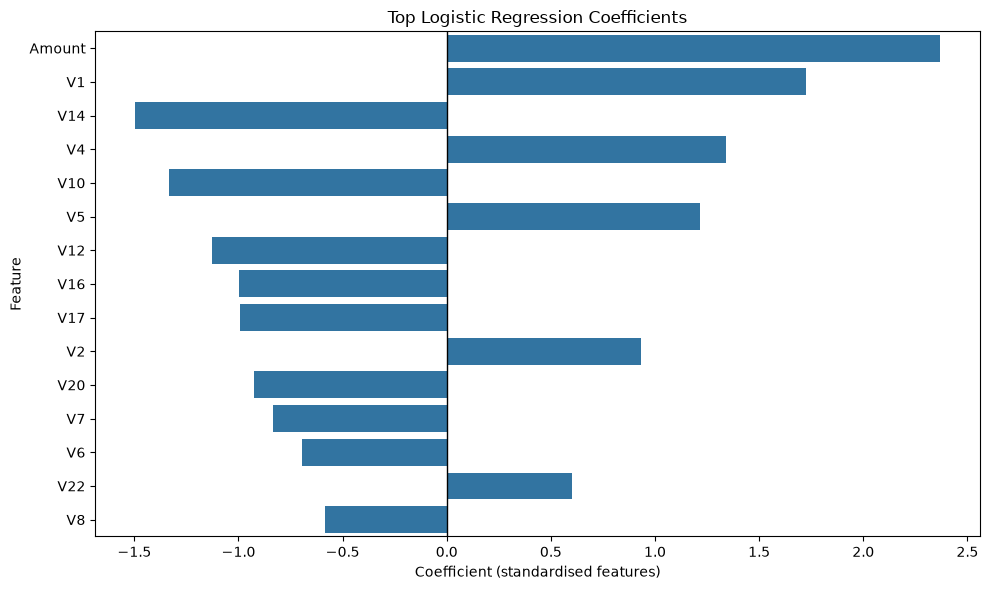

In [10]:

lr_model = models["Logistic Regression"].named_steps["classifier"]

coefficient_df = pd.DataFrame({
    "Feature": X_train.columns,
    "Coefficient": lr_model.coef_[0]
})

coefficient_df["Absolute Coefficient"] = coefficient_df["Coefficient"].abs()

coefficient_df = coefficient_df.sort_values(
    by="Absolute Coefficient",
    ascending=False
)

print("Top 15 Logistic Regression Coefficients:")
display(coefficient_df.head(15).round(5))

plt.figure(figsize=(10, 6))
sns.barplot(
    data=coefficient_df.head(15),
    x="Coefficient",
    y="Feature"
)
plt.axvline(0, color="black", linewidth=1)
plt.title("Top Logistic Regression Coefficients")
plt.xlabel("Coefficient (standardised features)")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()


## 8. Scalability Analysis: One Million Transactions per Hour

A production fraud detection system may need to process one million transactions per hour, which is approximately 278 transactions per second on average. The system must provide accurate predictions with low latency while handling sudden increases in transaction volume.

A scalable architecture could use Apache Kafka or a similar message queue to receive transaction events, a containerised prediction service built with FastAPI to serve the trained model, and horizontal scaling to distribute requests across multiple instances. Batch processing and optimised inference can improve throughput when immediate individual predictions are not required.

The system should monitor latency, throughput, false-positive rates, recall, data drift, and changes in fraud patterns. Models should be retrained and validated regularly using recent labelled data. Thresholds should be selected based on the financial cost of missed fraud and the operational cost of incorrectly flagging legitimate transactions.

Processing one million transactions per hour is an engineering target, not a guaranteed capability of the models developed in this notebook. Load testing, performance optimisation, secure data handling, and production monitoring would be required before deployment.

## 9. Precision vs Recall Trade-off

Precision measures how many transactions predicted as fraudulent are actually fraudulent. High precision reduces false alarms and avoids unnecessary interruptions to legitimate customers.

Recall measures how many of the actual fraudulent transactions are successfully detected. High recall is important because missed fraudulent transactions may cause financial losses.

Increasing recall may also increase false positives, reducing precision. Therefore, a fraud detection system should balance both metrics according to business requirements. For example, a bank may prioritise recall for high-risk transactions while using additional verification to reduce the impact on legitimate customers. The final decision threshold should be selected using validation data and the costs associated with false positives and false negatives.

## 10. Conclusion

This project developed machine learning models to identify potentially fraudulent credit card transactions using the Credit Card Fraud Detection dataset. The dataset was inspected for missing values, and exploratory data analysis highlighted the severe imbalance between legitimate and fraudulent transactions.

Stratified train-test splitting preserved the class distribution in both datasets. Logistic Regression and Random Forest were trained using class weighting to address the imbalance. The models were evaluated using Precision, Recall, F1-score, ROC-AUC, classification reports, and confusion matrices. Feature importance and Logistic Regression coefficients were also examined to understand the influence of transaction attributes.

The project demonstrates why accuracy alone is insufficient for fraud detection. The more suitable model should be selected based on its fraud detection performance, false-positive rate, operational requirements, and business costs. Further improvements could include threshold tuning, precision-recall analysis, hyperparameter optimisation, and testing on newer transaction data.